# Построение и исследование датчиков БСВ: МКМ и метод Мак-Ларена–Марсальи

**Вариант 12:** $a_0 = \beta = 161\,051$, $K = 192$, $M = 2^{31}$, $n = 1000$, уровень значимости $\varepsilon = 0.05$.

**План работы**
1. Моделирование $n=1000$ реализаций БСВ мультипликативным конгруэнтным методом (МКМ).
2. Моделирование $n=1000$ реализаций БСВ методом Мак-Ларена–Марсальи (первый датчик — МКМ из п. 1, второй — смешанный конгруэнтный датчик).
3. Проверка точности обоих датчиков критериями Колмогорова и $\chi^2$ Пирсона.

In [11]:
import math
import matplotlib.pyplot as plt

A0 = 161051          # a0 (начальное значение)
BETA = 161051        # множитель beta
M = 2**31            # модуль
K = 192              # объём вспомогательной таблицы
N = 1000             # число реализаций
EPS = 0.05           # уровень значимости
print("a0 =", A0, "| beta =", BETA, "| M =", M, "| K =", K, "| n =", N)

a0 = 161051 | beta = 161051 | M = 2147483648 | K = 192 | n = 1000


## 1. Мультипликативный конгруэнтный метод (МКМ)

Рекуррентная формула:

$$a_{k+1} = \beta\, a_k \pmod M,\qquad \alpha_k = \frac{a_k}{M},\qquad k = 1,2,\dots$$

Здесь $a_0 = \beta = 161051 = 11^5$ — нечётное число, при этом $\beta \bmod 8 = 3$. Для $M = 2^{s}$ ($s=31$) при нечётном $a_0$ и $\beta \equiv 3, 5 \pmod 8$ период последовательности максимален и равен $2^{s-2}=2^{29}$, что значительно больше $n=1000$.

Величины $\alpha_k\in(0,1)$ имитируют выборку из равномерного распределения $U(0,1)$ (БСВ).

In [21]:
def mcm(a0, beta, M, n):
    # Мультипликативный конгруэнтный датчик: a_{k+1} = beta * a_k mod M, alpha = a_k / M
    a = a0
    res = []
    for _ in range(n):
        a = (beta * a) % M
        res.append(a / M)
    return res

print("beta mod 8 =", BETA % 8, "| a0 нечётно:", A0 % 2 == 1)
alpha_mcm = mcm(A0, BETA, M, N)
print("Первые 10 значений МКМ:")
print([round(x, 6) for x in alpha_mcm[:10]])

beta mod 8 = 3 | a0 нечётно: True
Первые 10 значений МКМ:
[0.078055, 0.759974, 0.570956, 0.070699, 0.16809, 0.104183, 0.763891, 0.461761, 0.084476, 0.995599]


## 2. Метод Мак-Ларена–Марсальи

Метод «перемешивает» выход одного датчика с помощью другого, что уменьшает корреляции между соседними значениями.

**Алгоритм.** Пусть $\{b_i\}$ — последовательность первого датчика (МКМ), $\{c_i\}$ — последовательность второго датчика.

1. Заполняем вспомогательную таблицу $V = (V_0,\dots,V_{K-1})$ первыми $K$ значениями первого датчика: $V_j = b_j$.
2. На каждом шаге берём очередное значение $c_i$ второго датчика и вычисляем индекс
$$s = \lfloor K\, c_i \rfloor \in \{0,\dots,K-1\}.$$
3. Выдаём $\alpha_i = V_s$.
4. Заменяем $V_s$ новым значением первого датчика: $V_s = b_{K+i}$.
5. Повторяем п. 2–4 $n$ раз.

**Второй датчик (на выбор)** — смешанный (линейный) конгруэнтный метод:
$$x_{k+1} = (a\,x_k + c) \bmod M,\qquad c_k = \frac{x_k}{M},$$
с параметрами $a = 1103515245$, $c = 12345$, $M = 2^{31}$, $x_0 = 12345$ (классические параметры, удовлетворяющие условиям Халла–Добелла о полном периоде).

In [ ]:
def lcg(x0, a, c, M, n):
    # Смешанный конгруэнтный датчик: x_{k+1} = (a*x_k + c) mod M
    x = x0
    res = []
    for _ in range(n):
        x = (a * x + c) % M
        res.append(x / M)
    return res

def maclaren_marsaglia(gen_b, gen_c, K, n):
    # gen_b: список значений 1-го датчика (длина >= K+n)
    # gen_c: список значений 2-го датчика (длина >= n)
    V = gen_b[:K]                 # заполнение таблицы
    ptr = K                       # указатель на следующее значение 1-го датчика
    res = []
    for i in range(n):
        s = int(K * gen_c[i])     # индекс s = floor(K * c_i)
        res.append(V[s])          # выдаём V_s
        V[s] = gen_b[ptr]         # заменяем новым значением 1-го датчика
        ptr += 1
    return res

# 1-й датчик — МКМ из п.1 (нужно K + N значений), 2-й — смешанный КМ
b_seq = mcm(A0, BETA, M, K + N)
c_seq = lcg(12345, 1103515245, 12345, M, N)

alpha_mm = maclaren_marsaglia(b_seq, c_seq, K, N)
print("Первые 10 значений метода Мак-Ларена–Марсальи:")
print([round(x, 6) for x in alpha_mm[:10]])

Первые 10 значений метода Мак-Ларена–Марсальи:
[0.99138, 0.040112, 0.162288, 0.435943, 0.670598, 0.757899, 0.493784, 0.551069, 0.362474, 0.32737]


## 3. Проверка точности датчиков

Нужно проверить, что выборка $\alpha_1,\dots,\alpha_n$ от датчика не отличается от выборки равномерной случайной величины на $(0,1)$. Для этого проверяем гипотезу

$$H_0:\ \alpha_i\sim U(0,1),\quad F(x)=x,\ x\in[0,1],$$

против альтернативы $H_1$: распределение другое. Уровень значимости $\varepsilon=0.05$ — вероятность отвергнуть $H_0$, когда она на самом деле верна.

### 3.1 Критерий согласия Колмогорова

**Идея.** По выборке строим эмпирическую функцию распределения $F_n(x)$ и смотрим, насколько она отличается от теоретической $F(x)=x$. Если датчик хороший, отличие должно быть небольшим.

**Эмпирическая функция распределения** — доля элементов выборки, не превосходящих $x$:

$$F_n(x)=\frac{\#\{i:\ \alpha_i\le x\}}{n}.$$

Это ступенчатая функция: она равна 0 левее наименьшего значения, на каждом значении выборки подскакивает на $\frac1n$ и равна 1 правее наибольшего.

**Статистика критерия** — наибольшее вертикальное расстояние между $F_n$ и $F$:

$$D_n=\sup_x|F_n(x)-F(x)|.$$

**Как считать $D_n$.** Отсортируем выборку по возрастанию (вариационный ряд): $\alpha_{(1)}\le\alpha_{(2)}\le\dots\le\alpha_{(n)}$. Между соседними точками $F_n$ постоянна, а $F(x)=x$ растёт, поэтому наибольшее расстояние достигается у точек скачков. В точке $\alpha_{(i)}$ функция $F_n$ слева равна $\frac{i-1}{n}$, а справа $\frac in$. Проверяем обе стороны скачка:

$$D_n^+=\max_{1\le i\le n}\left(\frac in-\alpha_{(i)}\right),\qquad
D_n^-=\max_{1\le i\le n}\left(\alpha_{(i)}-\frac{i-1}{n}\right),\qquad
D_n=\max\{D_n^+,\,D_n^-\}.$$

**Какую величину сравниваем с порогом.** Если $H_0$ верна и $F$ непрерывна, то при больших $n$ распределение величины $\sqrt n\,D_n$ не зависит от $n$ и описывается функцией Колмогорова (теорема Колмогорова):

$$P\big(\sqrt n\,D_n\le x\big)\approx K(x)=1-2\sum_{k=1}^{\infty}(-1)^{k-1}e^{-2k^2x^2},\qquad x>0,$$

а при $x\le0$ считаем $K(x)=0$. Ряд сходится очень быстро, поэтому в расчёте достаточно взять несколько десятков членов.

**Критическое значение** $x_{1-\varepsilon}$ находим из уравнения

$$K(x_{1-\varepsilon})=1-\varepsilon.$$

Смысл: при верной $H_0$ величина $\sqrt n\,D_n$ превышает $x_{1-\varepsilon}$ лишь в доле $\varepsilon$ случаев. Для $\varepsilon=0.05$ получаем $x_{0.95}\approx1.3581$. В работе корень уравнения ищется численно методом бисекции.

**Правило принятия решения.**

* Если $\sqrt n\,D_n>x_{1-\varepsilon}$, то $H_0$ **отвергается**: отклонение $F_n$ от $F$ слишком велико, чтобы считать его случайным, и датчик признаётся неточным.
* Если $\sqrt n\,D_n\le x_{1-\varepsilon}$, то $H_0$ **не отвергается**: выборка не противоречит равномерному распределению.

**$p$-значение** — вероятность того, что при верной $H_0$ получится отклонение не меньше наблюдаемого:

$$p\approx1-K\big(\sqrt n\,D_n\big).$$

Условие $p<\varepsilon$ равносильно условию $\sqrt n\,D_n>x_{1-\varepsilon}$, то есть это тот же вывод, выраженный через вероятность.

In [31]:
def kolmogorov_cdf(x, terms=100):
    # K(x) = 1 - 2 * sum_{k>=1} (-1)^{k-1} exp(-2 k^2 x^2)
    if x <= 0:
        return 0.0
    s = 0.0
    for k in range(1, terms + 1):
        s += (-1) ** (k - 1) * math.exp(-2 * k * k * x * x)
    return 1 - 2 * s

def bisect_root(f, lo, hi, tol=1e-10):
    # поиск корня монотонной функции f методом бисекции (f(lo)<0<f(hi))
    while hi - lo > tol:
        mid = (lo + hi) / 2
        if f(mid) < 0:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2

def kolmogorov_test(sample, eps=0.05):
    n = len(sample)
    x = sorted(sample)
    d_plus = max((i + 1) / n - x[i] for i in range(n))
    d_minus = max(x[i] - i / n for i in range(n))
    Dn = max(d_plus, d_minus)
    stat = math.sqrt(n) * Dn
    p = 1 - kolmogorov_cdf(stat)
    crit = bisect_root(lambda t: kolmogorov_cdf(t) - (1 - eps), 0.3, 3.0)
    return {"Dn": Dn, "stat": stat, "crit": crit, "p": p, "reject": stat > crit}

print("Критическое значение Колмогорова при eps=0.05:",
      round(bisect_root(lambda t: kolmogorov_cdf(t) - 0.95, 0.3, 3.0), 4), "(табличное ≈ 1.3581)")

Критическое значение Колмогорова при eps=0.05: 1.3581 (табличное ≈ 1.3581)


### 3.2 Критерий согласия $\chi^2$ Пирсона

**Гипотеза.** $H_0$: выборка $\alpha_1,\dots,\alpha_n$ взята из $U(0,1)$, $F(x)=x$ на $[0,1]$.

**Построение.** Разобьём $[0,1]$ на $m$ равных интервалов
$$\Delta_j=\left[\tfrac{j-1}{m},\tfrac{j}{m}\right),\quad j=1,\dots,m.$$
Пусть $\nu_j$ — число $\alpha_i$, попавших в $\Delta_j$ ($\sum_j\nu_j=n$). Если $H_0$ верна, то вероятность попасть в $\Delta_j$ равна длине интервала:
$$p_j=\frac1m,$$
а ожидаемая частота равна $np_j=\dfrac nm$.

**Статистика Пирсона:**
$$\chi^2=\sum_{j=1}^{m}\frac{(\nu_j-np_j)^2}{np_j}=\frac mn\sum_{j=1}^m\nu_j^2-n.$$

**Теорема Пирсона.** Если $H_0$ верна и вероятности $p_j$ заданы заранее (не оцениваются по выборке), то при $n\to\infty$ статистика $\chi^2$ сходится по распределению к $\chi^2_r$ с
$$r=m-1$$
степенями свободы (одна степень теряется из-за связи $\sum_j\nu_j=n$). Приближение считается хорошим при $np_j\ge5$.

**Правило решения.** Пусть $\chi^2_{1-\varepsilon}(r)$ — квантиль уровня $1-\varepsilon$ распределения $\chi^2_r$.

* $\chi^2>\chi^2_{1-\varepsilon}(r)$ — $H_0$ **отвергается**;
* $\chi^2\le\chi^2_{1-\varepsilon}(r)$ — $H_0$ **не отвергается**.

$p$-значение: $p=1-F_{\chi^2_r}(\chi^2)$; $H_0$ отвергается, если $p<\varepsilon$.

**Вычисление функции распределения $\chi^2_r$.** Через регуляризованную неполную гамма-функцию:
$$F_{\chi^2_r}(x)=P\!\left(\tfrac r2,\tfrac x2\right),\qquad
P(a,z)=\frac{z^a e^{-z}}{\Gamma(a+1)}\sum_{k=0}^{\infty}\frac{z^k}{(a+1)(a+2)\cdots(a+k)}.$$
Ряд считаем до тех пор, пока очередной член не станет пренебрежимо малым. Квантиль $\chi^2_{1-\varepsilon}(r)$ находим из уравнения $F_{\chi^2_r}(x)=1-\varepsilon$ методом бисекции.

In [32]:
def gamma_P(a, z):
    # регуляризованная неполная гамма-функция P(a, z)
    if z <= 0:
        return 0.0
    term = 1.0 / a
    s = term
    k = 1
    while abs(term) > 1e-15 * abs(s):
        term *= z / (a + k)
        s += term
        k += 1
        if k > 10000: break
    return s * math.exp(-z + a * math.log(z) - math.lgamma(a))

def chi2_cdf(x, r):
    return gamma_P(r / 2, x / 2)

def chi2_quantile(q, r):
    return bisect_root(lambda t: chi2_cdf(t, r) - q, 0.0, 200.0)

def chi2_test(sample, m=10, eps=0.05):
    n = len(sample)
    nu = [0] * m
    for v in sample:
        j = int(v * m)
        if j == m: j = m - 1
        nu[j] += 1
    exp = n / m
    stat = sum((c - exp) ** 2 / exp for c in nu)
    r = m - 1
    crit = chi2_quantile(1 - eps, r)
    p = 1 - chi2_cdf(stat, r)
    return {"nu": nu, "stat": stat, "crit": crit, "p": p, "r": r, "reject": stat > crit}

print("Критическое значение хи-квадрат (r=9, eps=0.05):", round(chi2_quantile(0.95, 9), 4), "(табличное ≈ 16.919)")

Критическое значение хи-квадрат (r=9, eps=0.05): 16.919 (табличное ≈ 16.919)


## 4. Результаты

Применяем оба критерия к выборке МКМ (п. 1) и выборке метода Мак-Ларена–Марсальи (п. 2).

In [33]:
def report(name, sample):
    ks = kolmogorov_test(sample, EPS)
    ch = chi2_test(sample, 10, EPS)
    print("=" * 62)
    print(name)
    print("=" * 62)
    print("Критерий Колмогорова:")
    print(f"  D_n = {ks['Dn']:.5f},  sqrt(n)*D_n = {ks['stat']:.5f}")
    print(f"  критическое значение = {ks['crit']:.5f},  p-значение = {ks['p']:.5f}")
    print("  Вывод:", "H0 ОТВЕРГАЕТСЯ" if ks['reject'] else "H0 не отвергается (выборка согласуется с U(0,1))")
    print("Критерий хи-квадрат Пирсона (m = 10 интервалов):")
    print("  частоты nu_j:", ch['nu'])
    print(f"  chi2 = {ch['stat']:.4f},  критическое значение (r={ch['r']}) = {ch['crit']:.4f},  p-значение = {ch['p']:.5f}")
    print("  Вывод:", "H0 ОТВЕРГАЕТСЯ" if ch['reject'] else "H0 не отвергается (выборка согласуется с U(0,1))")
    return ks, ch

res_mcm = report("Датчик 1: мультипликативный конгруэнтный метод", alpha_mcm)
res_mm = report("Датчик 2: метод Мак-Ларена–Марсальи (K = 192)", alpha_mm)

Датчик 1: мультипликативный конгруэнтный метод
Критерий Колмогорова:
  D_n = 0.04314,  sqrt(n)*D_n = 1.36410
  критическое значение = 1.35810,  p-значение = 0.04839
  Вывод: H0 ОТВЕРГАЕТСЯ
Критерий хи-квадрат Пирсона (m = 10 интервалов):
  частоты nu_j: [110, 103, 104, 106, 98, 95, 119, 89, 95, 81]
  chi2 = 10.5800,  критическое значение (r=9) = 16.9190,  p-значение = 0.30560
  Вывод: H0 не отвергается (выборка согласуется с U(0,1))
Датчик 2: метод Мак-Ларена–Марсальи (K = 192)
Критерий Колмогорова:
  D_n = 0.04736,  sqrt(n)*D_n = 1.49754
  критическое значение = 1.35810,  p-значение = 0.02255
  Вывод: H0 ОТВЕРГАЕТСЯ
Критерий хи-квадрат Пирсона (m = 10 интервалов):
  частоты nu_j: [112, 102, 102, 106, 105, 106, 109, 85, 92, 81]
  chi2 = 9.8000,  критическое значение (r=9) = 16.9190,  p-значение = 0.36692
  Вывод: H0 не отвергается (выборка согласуется с U(0,1))


## 5. Визуализация

### 5.1 Гистограмма относительных частот

Отрезок $[0,1]$ разбиваем на $k=5$ интервалов одинаковой длины $\Delta=0{,}2$: $\Delta_j=[(j-1)\Delta,\ j\Delta)$, $j=1,\dots,5$ (границы $0;\,0{,}2;\,0{,}4;\,0{,}6;\,0{,}8;\,1$).

Пусть $m_j$ — число значений $\alpha_i$, попавших в $\Delta_j$. Тогда:

* относительная частота $\dfrac{m_j}{n}$ (она равна площади $S_j$ столбца);
* высота столбца $h_j=\dfrac{m_j}{n}:\Delta$, так что $S_j=h_j\Delta=\dfrac{m_j}{n}$.

Для $U(0,1)$ плотность $f(x)=1$, поэтому столбцы должны быть близки к высоте $h=1$ (красная линия), а сумма площадей равна 1.

МКМ | m_j = [213, 210, 193, 208, 176] | h_j = [1.065, 1.05, 0.965, 1.04, 0.88] | сумма площадей = 1.0
Мак-Ларен–Марсалья | m_j = [214, 208, 211, 194, 173] | h_j = [1.07, 1.04, 1.055, 0.97, 0.865] | сумма площадей = 1.0


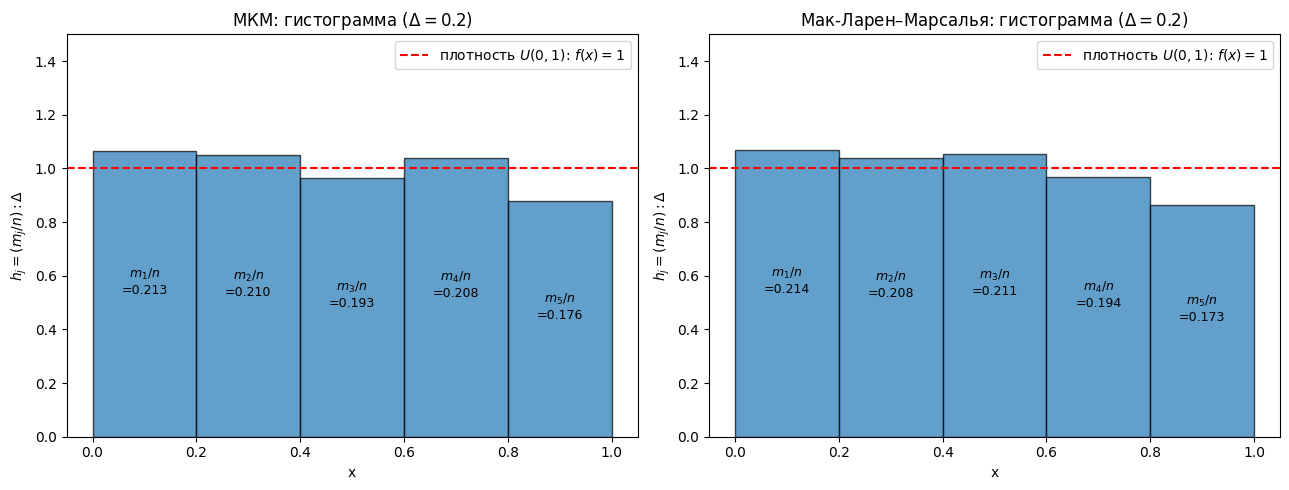

In [34]:
def histogram(sample, k=5):
    # возвращает границы интервалов, частоты m_j, относительные частоты m_j/n и высоты h_j
    n = len(sample)
    delta = 1 / k
    m = [0] * k
    for v in sample:
        j = int(v / delta)
        if j == k: j = k - 1
        m[j] += 1
    rel = [c / n for c in m]          # m_j / n
    h = [r / delta for r in rel]      # h_j = (m_j / n) / Delta
    edges = [j * delta for j in range(k + 1)]
    return edges, m, rel, h

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, smp) in zip(axes, [("МКМ", alpha_mcm), ("Мак-Ларен–Марсалья", alpha_mm)]):
    edges, m, rel, h = histogram(smp, 5)
    delta = 0.2
    ax.bar(edges[:-1], h, width=delta, align='edge', edgecolor='k', alpha=0.7)
    for j in range(5):
        ax.text(edges[j] + delta / 2, h[j] / 2, f"$m_{j+1}/n$\n={rel[j]:.3f}", ha='center', fontsize=9)
    ax.axhline(1, color='r', ls='--', label='плотность $U(0,1)$: $f(x)=1$')
    ax.set_xticks(edges)
    ax.set_ylim(0, 1.5)
    ax.set_xlabel("x"); ax.set_ylabel("$h_j = (m_j/n):\\Delta$")
    ax.set_title(f"{name}: гистограмма ($\\Delta=0.2$)")
    ax.legend(loc='upper right')
    print(name, "| m_j =", m, "| h_j =", [round(v, 3) for v in h], "| сумма площадей =", round(sum(h) * delta, 6))
plt.tight_layout(); plt.show()

### 5.2 Диаграмма рассеивания

Для выборки $X=(\alpha_1,\alpha_2,\alpha_3,\dots,\alpha_{1000})$, где $\alpha$ — БСВ, строим на единичном квадрате точки
$$M_1(\alpha_1,\alpha_2),\quad M_2(\alpha_2,\alpha_3),\quad\dots,\quad M_i(\alpha_i,\alpha_{i+1}),\quad i=1,\dots,999.$$

Если датчик качественный, точки равномерно заполняют квадрат $[0,1]^2$ без видимых закономерностей (полос, решёток, пустых областей). Полосы и линии говорят о корреляции соседних значений.

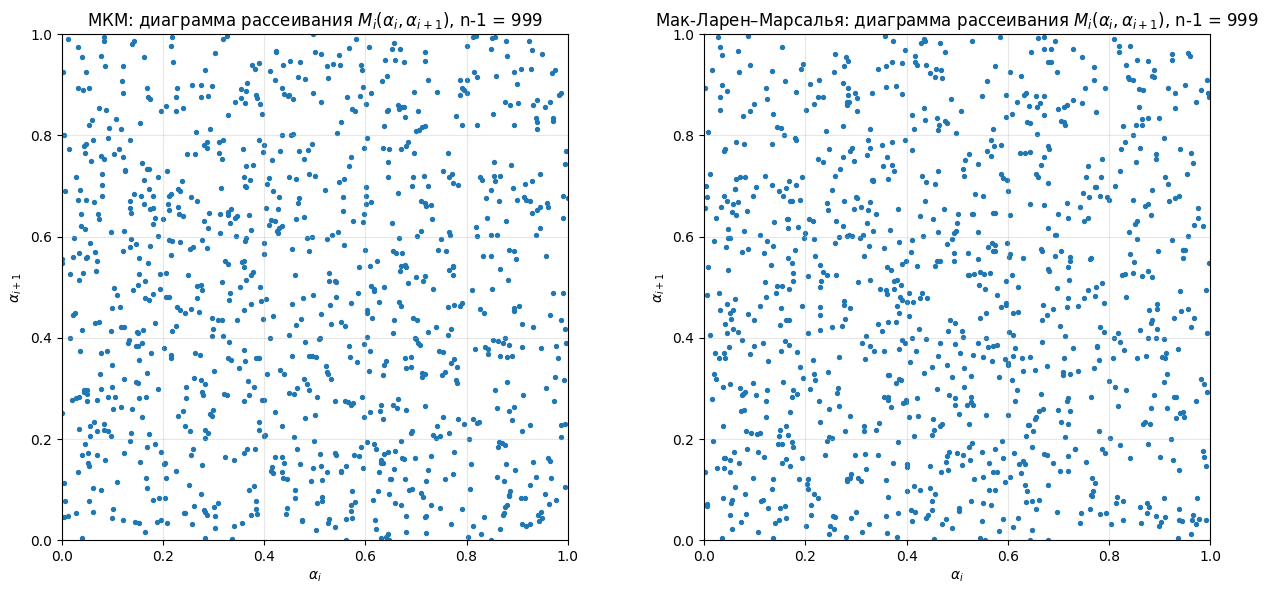

In [35]:
def scatter_points(sample):
    # точки M_i = (alpha_i, alpha_{i+1})
    return [sample[i] for i in range(len(sample) - 1)], [sample[i + 1] for i in range(len(sample) - 1)]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (name, smp) in zip(axes, [("МКМ", alpha_mcm), ("Мак-Ларен–Марсалья", alpha_mm)]):
    xs, ys = scatter_points(smp)
    ax.scatter(xs, ys, s=8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
    ax.set_xlabel("$\\alpha_i$"); ax.set_ylabel("$\\alpha_{i+1}$")
    ax.set_title(f"{name}: диаграмма рассеивания $M_i(\\alpha_i,\\alpha_{{i+1}})$, n-1 = {len(xs)}")
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [37]:
# Итоговая сводная таблица
print(f"{'Датчик':<26}{'sqrt(n)Dn':>11}{'крит.':>9}{'p (КС)':>10}{'chi2':>9}{'крит.':>9}{'p (chi2)':>10}")
for name, (ks, ch) in [("МКМ", res_mcm), ("Мак-Ларен–Марсалья", res_mm)]:
    print(f"{name:<26}{ks['stat']:>11.4f}{ks['crit']:>9.4f}{ks['p']:>10.4f}{ch['stat']:>9.4f}{ch['crit']:>9.4f}{ch['p']:>10.4f}")

Датчик                      sqrt(n)Dn    крит.    p (КС)     chi2    крит.  p (chi2)
МКМ                            1.3641   1.3581    0.0484  10.5800  16.9190    0.3056
Мак-Ларен–Марсалья             1.4975   1.3581    0.0225   9.8000  16.9190    0.3669
